## Task 1: Install PyTorch

In [ ]:
!pip install torch torchvision

In [ ]:
# import the libraries
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

print(torch.__version__)

2.11.0+cu130


## Task 2: Download and Load the Dataset

In [ ]:
# change images to tensors
transform = transforms.ToTensor()

# download MNIST
train_data = torchvision.datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_data = torchvision.datasets.MNIST(root='data', train=False, download=True, transform=transform)

# load data in batches of 32
train_loader = torch.utils.data.DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=32, shuffle=False)

print("number of training images:", len(train_data))
print("number of test images:", len(test_data))

number of training images: 60000
number of test images: 10000


## Task 3: Inspect the Dataset

In [ ]:
# get one batch from the train loader
images, labels = next(iter(train_loader))

print("images size:", images.shape)
print("labels size:", labels.shape)

images size: torch.Size([32, 1, 28, 28])
labels size: torch.Size([32])


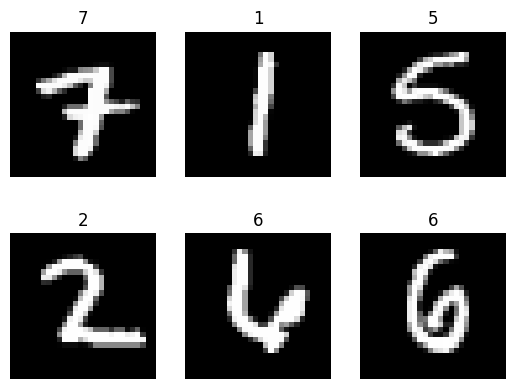

In [ ]:
# show some images
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i][0], cmap='gray')
    plt.title(labels[i].item())
    plt.axis('off')
plt.show()

## Task 4: Creating A Simple Network


In [ ]:
# import the neural network module
import torch.nn as nn

In [ ]:
# simple network: flatten -> linear -> relu -> linear
class SimpleNet(nn.Module):
    def __init__(self, input_size=784, hidden_size=128, num_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)   # input -> hidden
        self.relu = nn.ReLU()                           # nonlinearity
        self.fc2 = nn.Linear(hidden_size, num_classes)  # hidden -> output

    def forward(self, x):
        x = torch.flatten(x, 1)   # (N,1,28,28) -> (N,784)
        x = self.relu(self.fc1(x))
        return self.fc2(x)        # raw scores, no softmax

net = SimpleNet()
print(net)

# check shapes using the batch from task 3
print("input size:", images.shape)                   # (32, 1, 28, 28)
print("flattened size:", torch.flatten(images, 1).shape)  # (32, 784)
print("output size:", net(images).shape)             # (32, 10)


SimpleNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
input size: torch.Size([32, 1, 28, 28])
flattened size: torch.Size([32, 784])
output size: torch.Size([32, 10])


## Task 5: Implement the Training Function

In [ ]:
# Task 5: Implement the Training Function

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.9)

def train(model, train_loader, criterion, optimizer, epochs=5):
    train_losses = []
    train_accuracies = []

    for epoch in range(epochs):
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for batch_idx, (images, labels) in enumerate(train_loader):
            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backpropagation
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Calculate loss and accuracy
            running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            # Display batch information
            if (batch_idx + 1) % 500 == 0:
                print(
                    f"Epoch [{epoch + 1}/{epochs}], "
                    f"Batch [{batch_idx + 1}/{len(train_loader)}], "
                    f"Loss: {loss.item():.4f}"
                )

        # Calculate epoch loss and accuracy
        epoch_loss = running_loss / total
        epoch_accuracy = 100 * correct / total

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {epoch_accuracy:.2f}%"
        )

    return train_losses, train_accuracies


## Task 6: Train the Neural Network

In [ ]:
# Task 6: Train the Neural Network

train_losses, train_accuracies = train(
    model=net,
    train_loader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=5
)


Epoch [1/5], Batch [500/1875], Loss: 0.3698
Epoch [1/5], Batch [1000/1875], Loss: 0.4734
Epoch [1/5], Batch [1500/1875], Loss: 0.3986
Epoch [1/5] Loss: 0.3633 Accuracy: 89.77%
Epoch [2/5], Batch [500/1875], Loss: 0.0666
Epoch [2/5], Batch [1000/1875], Loss: 0.2959
Epoch [2/5], Batch [1500/1875], Loss: 0.1442
Epoch [2/5] Loss: 0.1639 Accuracy: 95.24%
Epoch [3/5], Batch [500/1875], Loss: 0.1917
Epoch [3/5], Batch [1000/1875], Loss: 0.0288
Epoch [3/5], Batch [1500/1875], Loss: 0.1776
Epoch [3/5] Loss: 0.1154 Accuracy: 96.71%
Epoch [4/5], Batch [500/1875], Loss: 0.0459
Epoch [4/5], Batch [1000/1875], Loss: 0.1085
Epoch [4/5], Batch [1500/1875], Loss: 0.1489
Epoch [4/5] Loss: 0.0903 Accuracy: 97.39%
Epoch [5/5], Batch [500/1875], Loss: 0.0556
Epoch [5/5], Batch [1000/1875], Loss: 0.0741
Epoch [5/5], Batch [1500/1875], Loss: 0.1194
Epoch [5/5] Loss: 0.0735 Accuracy: 97.84%


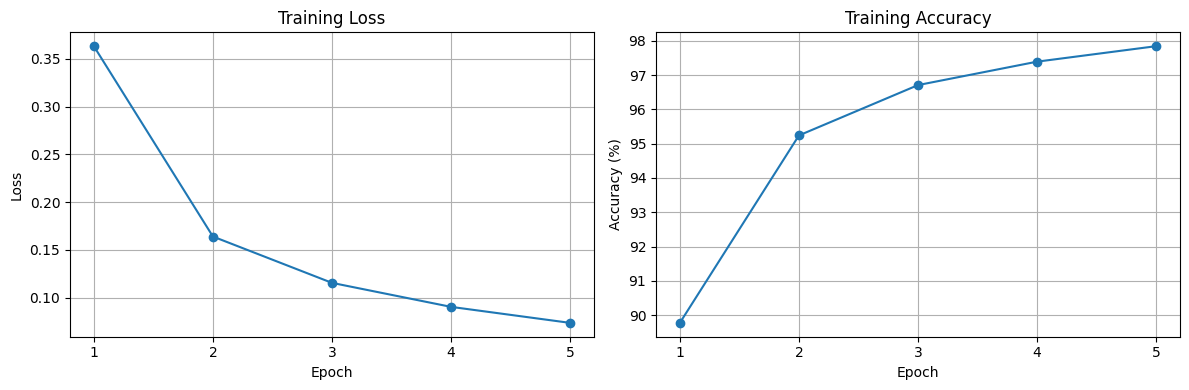

In [ ]:
# Task 6: Training Graphs

plt.figure(figsize=(12, 4))

# Training Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(range(1, len(train_losses) + 1))
plt.grid(True)

# Training Accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, len(train_accuracies) + 1), train_accuracies, marker='o')
plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.xticks(range(1, len(train_accuracies) + 1))
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

# Task 7: Test the Neural Network

net.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for test_images, test_labels in test_loader:
        outputs = net(test_images)
        loss = criterion(outputs, test_labels)

        test_loss += loss.item() * test_images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == test_labels).sum().item()
        total += test_labels.size(0)

test_loss = test_loss / total
test_accuracy = 100 * correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct Predictions: {correct}/{total}")


Test Loss: 0.0810
Test Accuracy: 97.53%
Correct Predictions: 9753/10000


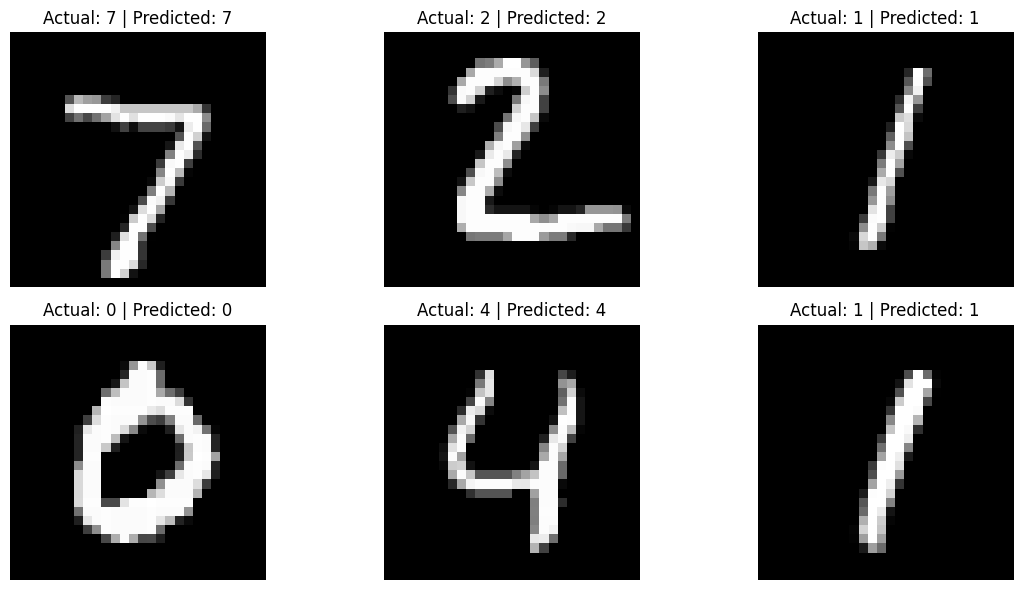

In [ ]:

# Display test images and predictions

import matplotlib.pyplot as plt

net.eval()

test_images, test_labels = next(iter(test_loader))

with torch.no_grad():
    outputs = net(test_images)
    predictions = outputs.argmax(dim=1)

plt.figure(figsize=(12, 6))

for i in range(6):
    plt.subplot(2, 3, i + 1)

    plt.imshow(test_images[i][0], cmap='gray')

    actual = test_labels[i].item()
    predicted = predictions[i].item()

    plt.title(f"Actual: {actual} | Predicted: {predicted}")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# Task 8: Hyperparameter Tuning

# Define parameter grids for grid search
learning_rates = [0.1, 0.01]
momentum_values = [0.5, 0.9]
tuning_results = []

# Perform grid search over learning rates and momentum values
for lr in learning_rates:
    for m in momentum_values:
        print(f"\n--- Training: Learning Rate = {lr} | Momentum = {m} ---")

        # Reinitialize model and optimizer using the existing setup
        tune_net = SimpleNet()
        tune_optimizer = optim.SGD(tune_net.parameters(), lr=lr, momentum=m)

        # Train the model
        losses, accuracies = train(
            model=tune_net,
            train_loader=train_loader,
            criterion=criterion,
            optimizer=tune_optimizer,
            epochs=5
        )

        # Store configuration results
        tuning_results.append({
            'lr': lr,
            'momentum': m,
            'final_loss': losses[-1],
            'final_accuracy': accuracies[-1]
        })

# Sort results to determine the best-performing configuration
sorted_results = sorted(tuning_results, key=lambda x: x['final_accuracy'], reverse=True)

# Display the final ranked results
print("\nRanked Tuning Results:")
for idx, res in enumerate(sorted_results, 1):
    print(f"{idx:02d}. LR: {res['lr']:<4} | Momentum: {res['momentum']:<3} -> Final Accuracy: {res['final_accuracy']:.2f}% | Loss: {res['final_loss']:.4f}")


--- Training: Learning Rate = 0.1 | Momentum = 0.5 ---
Epoch [1/5], Batch [500/1875], Loss: 0.0816
Epoch [1/5], Batch [1000/1875], Loss: 0.1704
Epoch [1/5], Batch [1500/1875], Loss: 0.1813
Epoch [1/5] Loss: 0.2721 Accuracy: 92.05%
Epoch [2/5], Batch [500/1875], Loss: 0.0647
Epoch [2/5], Batch [1000/1875], Loss: 0.1745
Epoch [2/5], Batch [1500/1875], Loss: 0.1407
Epoch [2/5] Loss: 0.1156 Accuracy: 96.56%
Epoch [3/5], Batch [500/1875], Loss: 0.0312
Epoch [3/5], Batch [1000/1875], Loss: 0.0357
Epoch [3/5], Batch [1500/1875], Loss: 0.1422
Epoch [3/5] Loss: 0.0816 Accuracy: 97.48%
Epoch [4/5], Batch [500/1875], Loss: 0.0237
Epoch [4/5], Batch [1000/1875], Loss: 0.0570
Epoch [4/5], Batch [1500/1875], Loss: 0.1361
Epoch [4/5] Loss: 0.0639 Accuracy: 97.98%
Epoch [5/5], Batch [500/1875], Loss: 0.1127
Epoch [5/5], Batch [1000/1875], Loss: 0.0283
Epoch [5/5], Batch [1500/1875], Loss: 0.2179
Epoch [5/5] Loss: 0.0506 Accuracy: 98.46%

--- Training: Learning Rate = 0.1 | Momentum = 0.9 ---
Epoch [1